# CS207 - Data functions

Imports

In [117]:
import sys
import numpy

import matplotlib.pyplot as plt
colors_ham_spam = ["#ff7dfb", "#ffcf69"]

import sklearn
import random
import statistics

import csv

#### Seed

In [118]:
random_seed = random.seed(10)

### Opening CSV as "data"

In [119]:
with open("spam.csv", "r", encoding="cp1252") as file:
  reader = csv.reader(file)
  data = list(reader)

## **Data clean up**

Identifying data in each row

In [120]:
print("Column count:", len(data[0]))
print("Headers:", data[0])

# Find rows with extra data and try to understand it
print("Rows with extra data:")
found = 0
for i, row in enumerate(data[1:], start=1):
  if any(row[2:]):
    print(f"Row {i}: {row}")
    found += 1
    
    if found == 10:
      break

# Try joining row 96 to see if it makes sense
row = data[96]
print(row[1:])
print(",".join(row[1:]))

Column count: 5
Headers: ['v1', 'v2', '', '', '']
Rows with extra data:
Row 96: ['spam', 'Your free ringtone is waiting to be collected. Simply text the password \\MIX\\" to 85069 to verify. Get Usher and Britney. FML', ' PO Box 5249', ' MK17 92H. 450Ppw 16"', '']
Row 282: ['ham', '\\Wen u miss someone', ' the person is definitely special for u..... But if the person is so special', ' why to miss them', ' just Keep-in-touch\\" gdeve.."']
Row 445: ['ham', '\\HEY HEY WERETHE MONKEESPEOPLE SAY WE MONKEYAROUND! HOWDY GORGEOUS', ' HOWU DOIN? FOUNDURSELF A JOBYET SAUSAGE?LOVE JEN XXX\\""', '', '']
Row 672: ['spam', 'SMS. ac sun0819 posts HELLO:\\You seem cool', ' wanted to say hi. HI!!!\\" Stop? Send STOP to 62468"', '', '']
Row 711: ['ham', 'Height of Confidence: All the Aeronautics professors wer calld &amp; they wer askd 2 sit in an aeroplane. Aftr they sat they wer told dat the plane ws made by their students. Dey all hurried out of d plane.. Bt only 1 didnt move... He said:\\if it is ma

---

#### **I love CS207, but it does not love me back, TAT**

| 0 | 1 | 2 | 3 |
|---|---|---|---|
|ham|"I love CS207 | but it does not love me back | TAT |

CSV columns are separated by ","
some commas are part of a message, but separated any way.

We will clean it up by joining the second column onwards.
The data will become only:

| 0 | 1 |
|---|---|
|ham|"I love CS207, but it does not love me back, TAT" |


In [121]:
joined_data = [["v1", "v2"]]

for row in data[1:]:
  message_parts = row[1:]
  
  # Remove column with empty value before joining
  while message_parts and message_parts[-1] == "":
    message_parts.pop()
  
  row_data = []
  row_data.append(row[0])
  row_data.append(",".join(message_parts))
  
  joined_data.append(row_data)

### Sanity check ###

# Total rows and column
print("Total rows:", len(joined_data))
print("Columns per row:", len(joined_data[1]))

empty_labels = 0			# labels : ham / spam
empty_messages = 0

for row in joined_data[1:]:
  if row[0] == "":
    empty_labels += 1
    
  if row[1] == "":
    empty_messages += 1
    
print("Empty labels:", empty_labels)
print("Empty messages:", empty_messages)

# Label check (Make sure that there's only "ham" and "spam")
labels = set()

for row in joined_data[1:]:
    labels.add(row[0])

print(labels)

Total rows: 5573
Columns per row: 2
Empty labels: 0
Empty messages: 0
{'spam', 'ham'}


No empty labels and messages after joining. 🎉

---
### **Separating data (ham and spam)**

In [122]:
headers = [joined_data[0]]
ham = []
spam = []

for row in joined_data[1:]:
  if row[0] == "ham":
    ham.append(row)
  elif row[0] == "spam":
    spam.append(row)

Distribution visualization

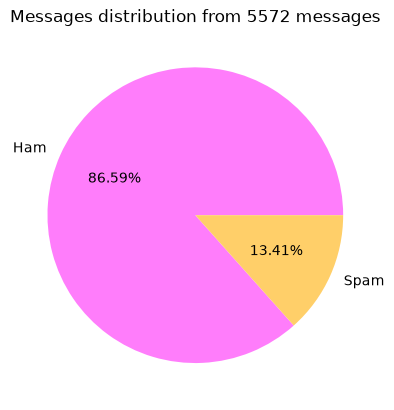

In [123]:
labels = ["Ham", "Spam"]
counts = [len(ham), len(spam)]
all_messages = sum(counts)

plt.title(f"Messages distribution from {all_messages} messages")
plt.pie(
  counts,
  labels=labels,
  colors=colors_ham_spam,
  autopct="%1.2f%%")
plt.show()

---

### **Identifying features of the messages**

##### **Average words**

In [124]:
ham_word_counts = []
spam_word_counts = []

for row in ham:
  message = row[1]
  words = message.split()
  ham_word_counts.append(len(words))
  
for row in spam:
  message = row[1]
  words = message.split()
  spam_word_counts.append(len(words))
  
ham_average_word_count = sum(ham_word_counts) / len(ham)
spam_average_word_count = sum(spam_word_counts) / len(spam)

#### Bar chart

<BarContainer object of 2 artists>

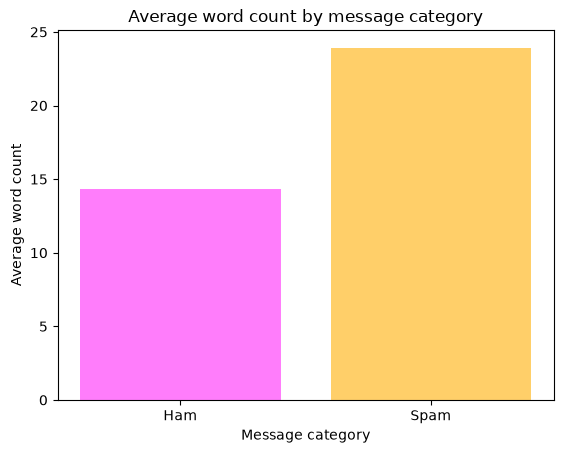

In [125]:
labels = ["Ham", "Spam"]
averages = [ham_average_word_count, spam_average_word_count]

plt.title("Average word count by message category")
plt.xlabel("Message category")
plt.ylabel("Average word count")

plt.bar(labels, averages, color=colors_ham_spam)

#### Histogram

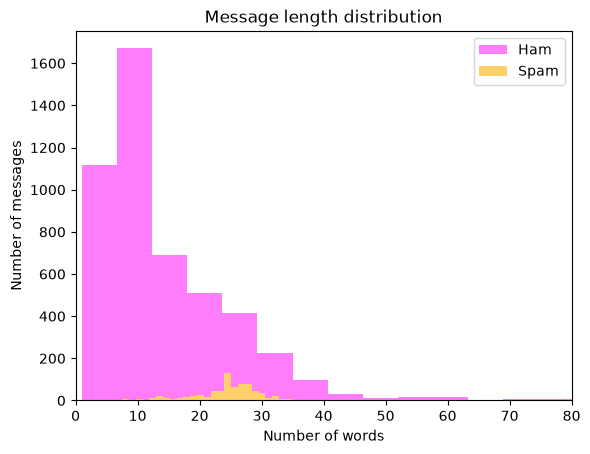

In [126]:
plt.title("Message length distribution")
plt.xlabel("Number of words")
plt.ylabel("Number of messages")

plt.hist(
    ham_word_counts,
    bins=30,
    color=colors_ham_spam[0],
    label="Ham"
)

plt.hist(
    spam_word_counts,
    bins=30,
    color=colors_ham_spam[1],
    label="Spam"
)

# Limit the x axis of the visualization
# Messages length are concentrated around 0-50 words
plt.xlim(0, 80)
plt.xticks(range(0, 81, 10))

plt.legend()
plt.show()

> Ham: Most ham messages contain around 10-16 words per message.
>
> Spam: Messages tends to be longer, it has a higher average word count around low-to-mid 20s.

#### **The big 3 - Mean, Median, Mode**

#### Mean

In [127]:
ham_mean = ham_average_word_count
spam_mean = spam_average_word_count

print("Ham mean:", round(ham_mean, 2))
print("Spam mean:", round(spam_mean, 2))

Ham mean: 14.31
Spam mean: 23.91


##### Median

In [128]:
ham_sorted = sorted(ham_word_counts)
spam_sorted = sorted(spam_word_counts)

ham_middle = len(ham_sorted) // 2
spam_middle = len(spam_sorted) // 2

ham_median = (
	ham_sorted[ham_middle - 1] + ham_sorted[ham_middle]
) / 2

spam_median = (
	spam_sorted[spam_middle - 1] + spam_sorted[spam_middle]
) / 2

print("Ham median:", ham_median)
print("Spam median:", spam_median)

Ham median: 11.0
Spam median: 25.0


##### Mode

In [129]:
ham_word_frequencies = {}

# Go through all numbers of word counts, add to a dict.
for word_count in ham_word_counts:
  if word_count not in ham_word_frequencies:
    ham_word_frequencies[word_count] = 1
  else:
    ham_word_frequencies[word_count] += 1

# Find mode by sorting and then pick the first value
sorted_ham_frequencies = sorted(
  ham_word_frequencies.items(),
  key=lambda item: item[1],
  reverse=True
)

ham_mode = sorted_ham_frequencies[0][0]

In [130]:
spam_word_frequencies = {}

for word_count in spam_word_counts:
    if word_count not in spam_word_frequencies:
        spam_word_frequencies[word_count] = 1
    else:
        spam_word_frequencies[word_count] += 1

sorted_spam_frequencies = sorted(
    spam_word_frequencies.items(),
    key=lambda item: item[1],
    reverse=True
)

spam_mode = sorted_spam_frequencies[0][0]


In [131]:
print("Ham mode:", ham_mode)
print("Spam mode:", spam_mode)

Ham mode: 6
Spam mode: 27


### Measures of central tendency

| Statistic | Ham | Spam |
|---|---|---|
| Mean | 14.31 | 23.91 |
| Median | 11.00 | 25.00 |
| Mode | 6 | 27 |

---

### **Standard deviation**

In [132]:
ham_squared_differences = []

for word_count in ham_word_counts:
  difference = word_count - ham_mean
  squared_differences = difference ** 2
  ham_squared_differences.append(squared_differences)

In [133]:
spam_squared_differences = []

for word_count in spam_word_counts:
  difference = word_count - spam_mean
  squared_differences = difference ** 2
  spam_squared_differences.append(squared_differences)

### **Variance**

In [ ]:
ham_variance = sum(ham_squared_differences) / len(ham_squared_differences)
spam_variance = sum(spam_squared_differences) / len(spam_squared_differences)

print(ham_variance)
print(spam_variance)

132.42
33.37


| Values | Ham | Spam |
|---|---|---|
| Variance | 132.42 | 33.37 |